In [1]:
import pandas as pd
import numpy as np

In [2]:
train_data = pd.read_csv('train.csv')
store_data = pd.read_csv('store.csv')


C:\Users\HP\AppData\Local\Temp\ipykernel_26772\2029645938.py:1: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  train_data = pd.read_csv('train.csv')


In [3]:
train_data

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1
...,...,...,...,...,...,...,...,...,...
1017204,1111,2,2013-01-01,0,0,0,0,a,1
1017205,1112,2,2013-01-01,0,0,0,0,a,1
1017206,1113,2,2013-01-01,0,0,0,0,a,1
1017207,1114,2,2013-01-01,0,0,0,0,a,1


In [4]:
store_data

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
1110,1111,a,a,1900.0,6.0,2014.0,1,31.0,2013.0,"Jan,Apr,Jul,Oct"
1111,1112,c,c,1880.0,4.0,2006.0,0,NaN,NaN,NaN
1112,1113,a,c,9260.0,NaN,NaN,0,NaN,NaN,NaN
1113,1114,a,c,870.0,NaN,NaN,0,NaN,NaN,NaN


In [5]:
# data preprocessing
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')
sns.set(style='whitegrid')


In [6]:
train_data.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


In [7]:
train_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype 
---  ------         --------------    ----- 
 0   Store          1017209 non-null  int64 
 1   DayOfWeek      1017209 non-null  int64 
 2   Date           1017209 non-null  object
 3   Sales          1017209 non-null  int64 
 4   Customers      1017209 non-null  int64 
 5   Open           1017209 non-null  int64 
 6   Promo          1017209 non-null  int64 
 7   StateHoliday   1017209 non-null  object
 8   SchoolHoliday  1017209 non-null  int64 
dtypes: int64(7), object(2)
memory usage: 69.8+ MB


In [8]:
missing = train_data.isnull().sum()
missing=missing[missing > 0]


In [9]:
missing_precentage=((missing/train_data.shape[0])*100).sort_values(ascending=False)
missing_precentage[missing_precentage>0]

Series([], dtype: float64)

In [10]:
missing_precentage

Series([], dtype: float64)

In [11]:
train_data['Date']= pd.to_datetime(train_data['Date'])

In [12]:
train_data['Date'].dtypes

dtype('<M8[ns]')

In [13]:
train_data = train_data.sort_values(by='Date').reset_index(drop=True)

In [14]:
train_data

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1115,2,2013-01-01,0,0,0,0,a,1
1,379,2,2013-01-01,0,0,0,0,a,1
2,378,2,2013-01-01,0,0,0,0,a,1
3,377,2,2013-01-01,0,0,0,0,a,1
4,376,2,2013-01-01,0,0,0,0,a,1
...,...,...,...,...,...,...,...,...,...
1017204,746,5,2015-07-31,9082,638,1,1,0,1
1017205,747,5,2015-07-31,10708,826,1,1,0,1
1017206,748,5,2015-07-31,7481,578,1,1,0,1
1017207,742,5,2015-07-31,10460,1016,1,1,0,1


In [15]:
print("Duplicate rows:", train_data.duplicated().sum())

Duplicate rows: 0


In [16]:
print("Minimum Sales:", train_data["Sales"].min())
print("Maximum Sales:", train_data["Sales"].max())
print("Average Sales:", train_data["Sales"].mean())

Minimum Sales: 0
Maximum Sales: 41551
Average Sales: 5773.818972305593


In [17]:
print("Zero sales:", (train_data["Sales"] == 0).sum())

Zero sales: 172871


In [18]:
train_data["Open"].value_counts()

Open
1    844392
0    172817
Name: count, dtype: int64

In [19]:
df_open = train_data[train_data["Open"] == 1].copy()

print(df_open.shape)

(844392, 9)


In [20]:
print("Day of Week:")
print(train_data["DayOfWeek"].value_counts().sort_index())

print("\nPromo:")
print(train_data["Promo"].value_counts())

print("\nState Holiday:")
print(train_data["StateHoliday"].value_counts())

print("\nSchool Holiday:")
print(train_data["SchoolHoliday"].value_counts())

Day of Week:
DayOfWeek
1    144730
2    145664
3    145665
4    145845
5    145845
6    144730
7    144730
Name: count, dtype: int64

Promo:
Promo
0    629129
1    388080
Name: count, dtype: int64

State Holiday:
StateHoliday
0    855087
0    131072
a     20260
b      6690
c      4100
Name: count, dtype: int64

School Holiday:
SchoolHoliday
0    835488
1    181721
Name: count, dtype: int64


In [21]:
train_data = train_data[train_data["Open"] == 1].copy()

train_data = train_data.sort_values("Date").reset_index(drop=True)

In [22]:
train_data

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,353,2,2013-01-01,3139,820,1,0,a,1
1,733,2,2013-01-01,10765,2377,1,0,a,1
2,562,2,2013-01-01,8498,1675,1,0,a,1
3,676,2,2013-01-01,3821,777,1,0,a,1
4,682,2,2013-01-01,3375,566,1,0,a,1
...,...,...,...,...,...,...,...,...,...
844387,6,5,2015-07-31,5651,589,1,1,0,1
844388,5,5,2015-07-31,4822,559,1,1,0,1
844389,4,5,2015-07-31,13995,1498,1,1,0,1
844390,10,5,2015-07-31,7185,681,1,1,0,1


In [23]:
print("Final Shape:", train_data.shape)

print("\nMissing Values:")
print(train_data.isnull().sum())

print("\nDuplicates:", train_data.duplicated().sum())

Final Shape: (844392, 9)

Missing Values:
Store            0
DayOfWeek        0
Date             0
Sales            0
Customers        0
Open             0
Promo            0
StateHoliday     0
SchoolHoliday    0
dtype: int64

Duplicates: 0


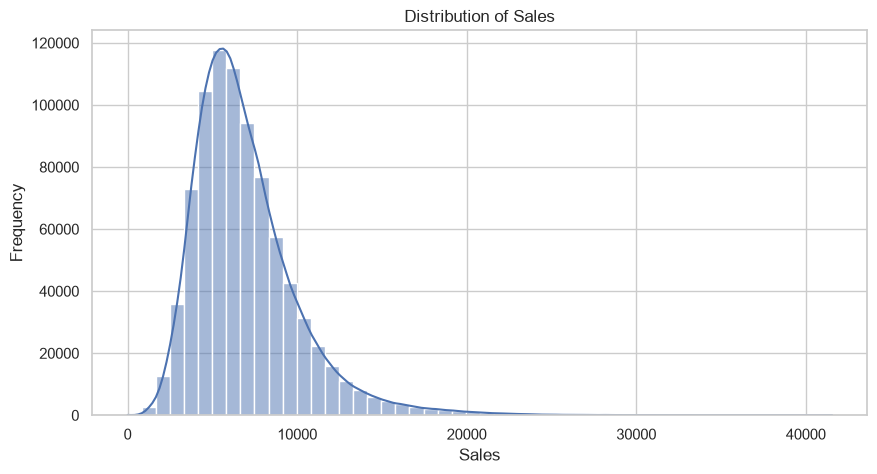

In [24]:
#EDA
plt.figure(figsize=(10, 5))

sns.histplot(train_data["Sales"], bins=50, kde=True)

plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")

plt.show()

In [25]:
daily_sales = (
    train_data.groupby("Date")["Sales"]
      .sum()
      .reset_index()
)

daily_sales.head()


,Date,Sales
0,2013-01-01,97235
1,2013-01-02,6949829
2,2013-01-03,6347820
3,2013-01-04,6638954
4,2013-01-05,5951593


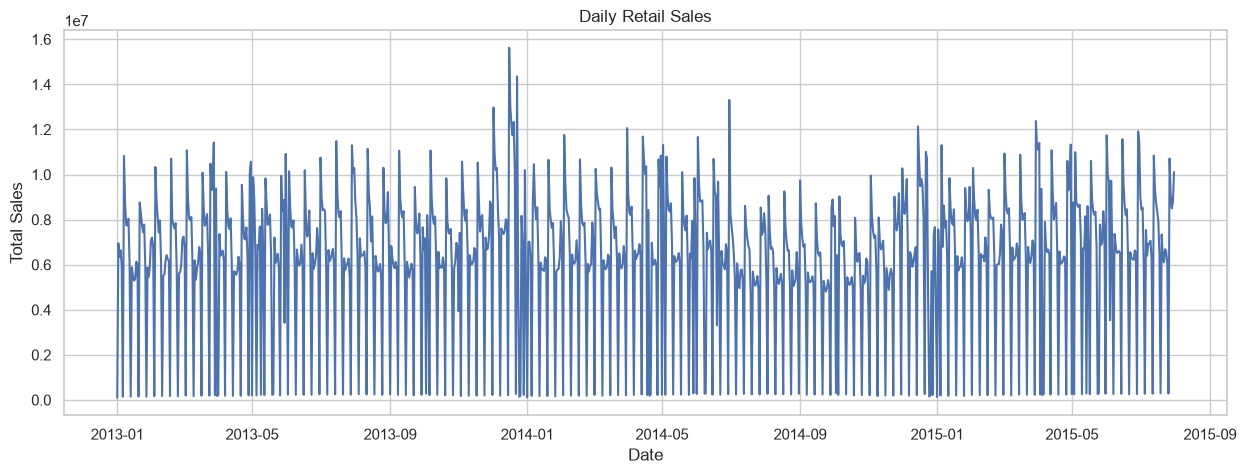

In [26]:
plt.figure(figsize=(15, 5))

plt.plot(
    daily_sales["Date"],
    daily_sales["Sales"]
)

plt.title("Daily Retail Sales")
plt.xlabel("Date")
plt.ylabel("Total Sales")

plt.show()

In [27]:
train_data["Month"] = train_data["Date"].dt.month
train_data["Year"] = train_data["Date"].dt.year

In [28]:
monthly_sales = (
    train_data.groupby(["Year", "Month"])["Sales"]
      .sum()
      .reset_index()
)

monthly_sales.head()

,Year,Month,Sales
0,2013,1,180132207
1,2013,2,171534275
2,2013,3,201180369
3,2013,4,183431432
4,2013,5,185411063


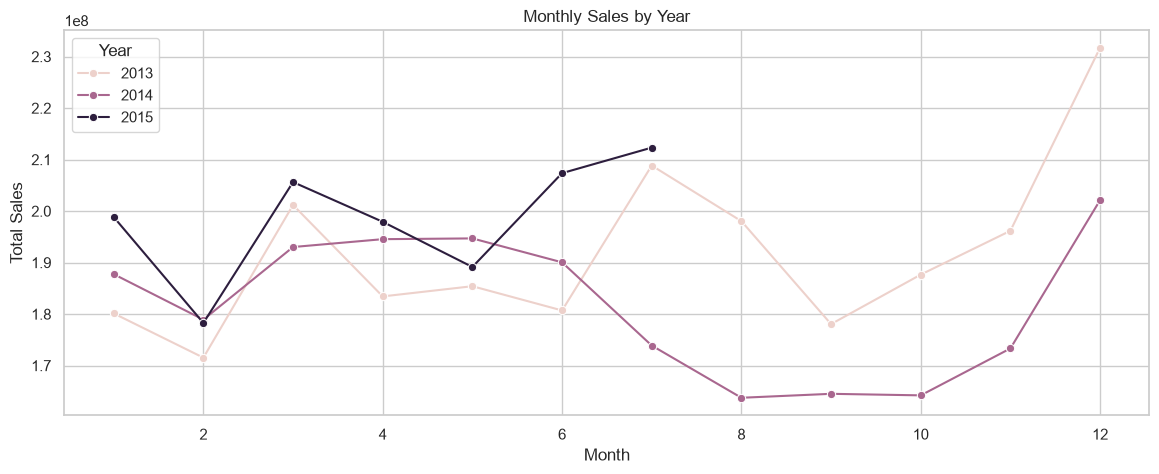

In [29]:
plt.figure(figsize=(14, 5))

sns.lineplot(
    data=monthly_sales,
    x="Month",
    y="Sales",
    hue="Year",
    marker="o"
)

plt.title("Monthly Sales by Year")
plt.xlabel("Month")
plt.ylabel("Total Sales")

plt.show()

In [30]:
day_sales = (
    train_data.groupby("DayOfWeek")["Sales"]
      .mean()
      .reset_index()
)

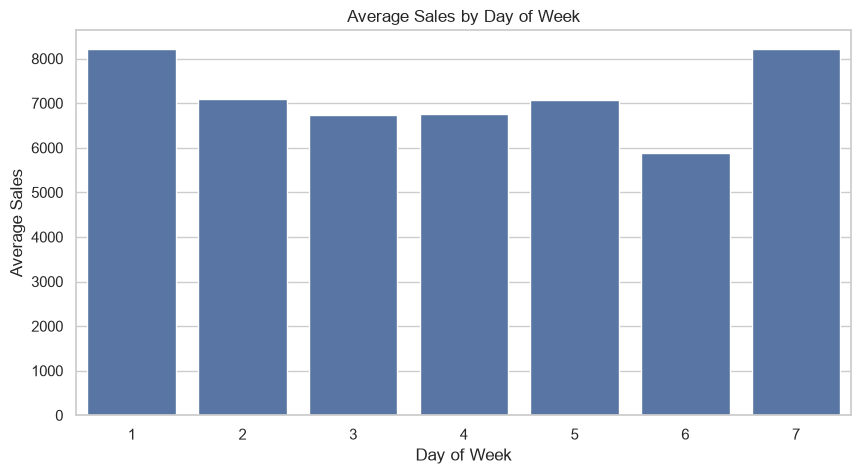

In [31]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=day_sales,
    x="DayOfWeek",
    y="Sales"
)

plt.title("Average Sales by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Sales")

plt.show()

In [32]:
promo_sales = (
    train_data.groupby("Promo")["Sales"]
      .mean()
      .reset_index()
)

promo_sales

,Promo,Sales
0,0,5929.407603
1,1,8228.281239


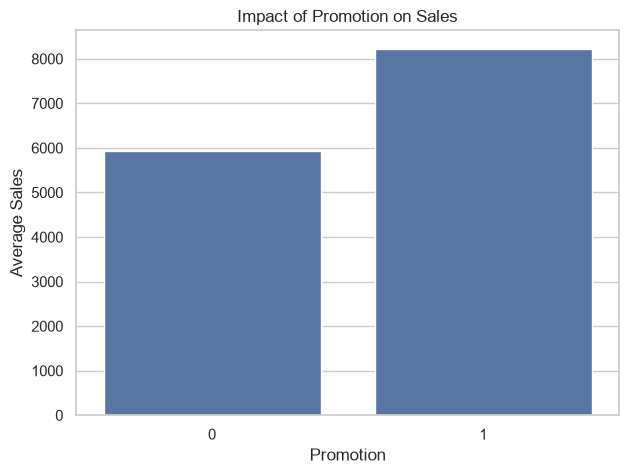

In [33]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=promo_sales,
    x="Promo",
    y="Sales"
)

plt.title("Impact of Promotion on Sales")
plt.xlabel("Promotion")
plt.ylabel("Average Sales")

plt.show()

In [34]:
top_stores = (
    train_data.groupby("Store")["Sales"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

top_stores

Store
262     19516842
817     17057867
562     16927322
1114    16202585
251     14896870
513     14252406
788     14082141
733     14067158
383     13489879
756     12911782
Name: Sales, dtype: int64

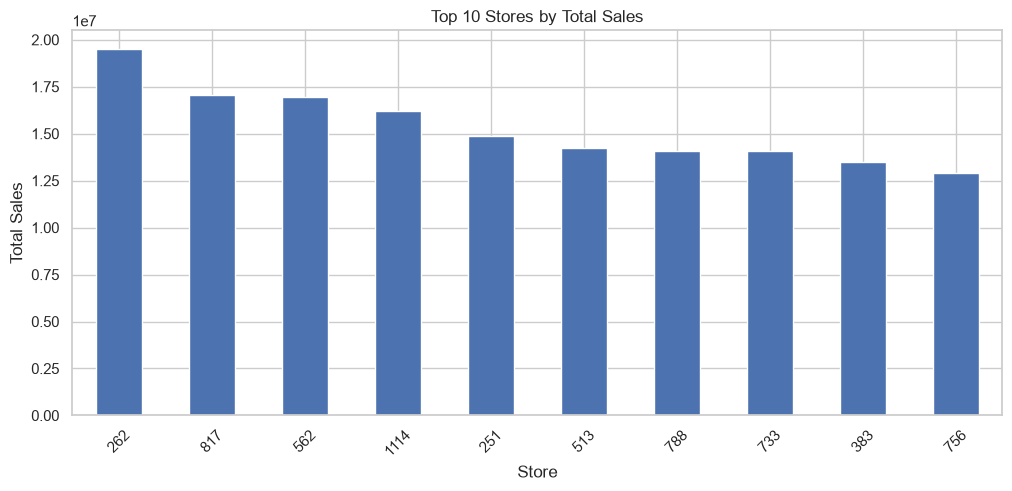

In [35]:
plt.figure(figsize=(12, 5))

top_stores.plot(kind="bar")

plt.title("Top 10 Stores by Total Sales")
plt.xlabel("Store")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)

plt.show()

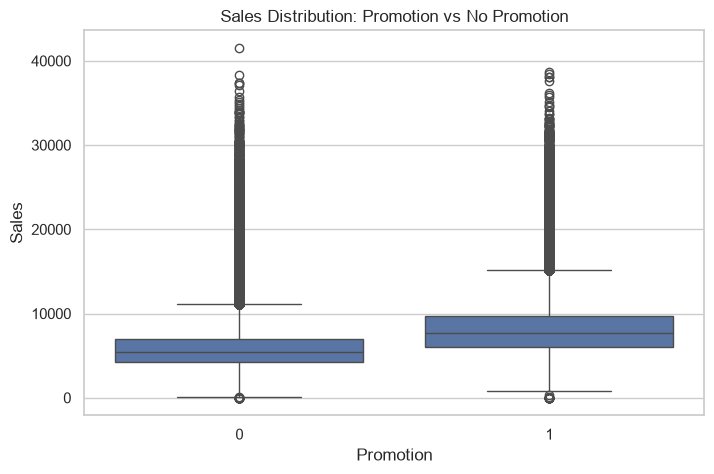

In [36]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=train_data,
    x="Promo",
    y="Sales"
)

plt.title("Sales Distribution: Promotion vs No Promotion")
plt.xlabel("Promotion")
plt.ylabel("Sales")

plt.show()

In [37]:
holiday_sales = (
    train_data.groupby("SchoolHoliday")["Sales"]
      .mean()
      .reset_index()
)

holiday_sales

,SchoolHoliday,Sales
0,0,6896.782411
1,1,7200.181650


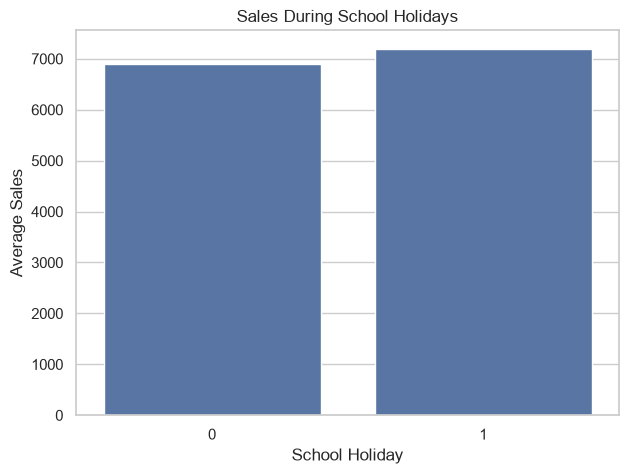

In [38]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=holiday_sales,
    x="SchoolHoliday",
    y="Sales"
)

plt.title("Sales During School Holidays")
plt.xlabel("School Holiday")
plt.ylabel("Average Sales")

plt.show()

In [39]:
model_df = train_data.copy()

In [40]:
model_df["Year"] = model_df["Date"].dt.year
model_df["Month"] = model_df["Date"].dt.month
model_df["Day"] = model_df["Date"].dt.day
model_df["DayOfWeek"] = model_df["Date"].dt.dayofweek
model_df["WeekOfYear"] = model_df["Date"].dt.isocalendar().week.astype(int)

In [41]:
model_df["IsWeekend"] = (
    model_df["DayOfWeek"] >= 5
).astype(int)

In [42]:
model_df[
    [
        "Date",
        "Year",
        "Month",
        "Day",
        "DayOfWeek",
        "WeekOfYear",
        "IsWeekend"
    ]
].head()

,Date,Year,Month,Day,DayOfWeek,WeekOfYear,IsWeekend
0,2013-01-01,2013,1,1,1,1,0
1,2013-01-01,2013,1,1,1,1,0
2,2013-01-01,2013,1,1,1,1,0
3,2013-01-01,2013,1,1,1,1,0
4,2013-01-01,2013,1,1,1,1,0


In [43]:
model_df["Lag_1"] = (
    model_df
    .groupby("Store")["Sales"]
    .shift(1)
)

In [44]:
model_df["Lag_7"] = (
    model_df
    .groupby("Store")["Sales"]
    .shift(7)
)

In [45]:
model_df["Lag_14"] = (
    model_df
    .groupby("Store")["Sales"]
    .shift(14)
)

In [46]:
model_df["Lag_30"] = (
    model_df
    .groupby("Store")["Sales"]
    .shift(30)
)

In [47]:
model_df["Rolling_7"] = (
    model_df
    .groupby("Store")["Sales"]
    .transform(
        lambda x: x.shift(1).rolling(7).mean()
    )
)

In [48]:
model_df["Rolling_30"] = (
    model_df
    .groupby("Store")["Sales"]
    .transform(
        lambda x: x.shift(1).rolling(30).mean()
    )
)

In [49]:
model_df.head(15)

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,Month,Year,Day,WeekOfYear,IsWeekend,Lag_1,Lag_7,Lag_14,Lag_30,Rolling_7,Rolling_30
0,353,1,2013-01-01,3139,820,1,0,a,1,1,2013,1,1,0,NaN,NaN,NaN,NaN,NaN,NaN
1,733,1,2013-01-01,10765,2377,1,0,a,1,1,2013,1,1,0,NaN,NaN,NaN,NaN,NaN,NaN
2,562,1,2013-01-01,8498,1675,1,0,a,1,1,2013,1,1,0,NaN,NaN,NaN,NaN,NaN,NaN
3,676,1,2013-01-01,3821,777,1,0,a,1,1,2013,1,1,0,NaN,NaN,NaN,NaN,NaN,NaN
4,682,1,2013-01-01,3375,566,1,0,a,1,1,2013,1,1,0,NaN,NaN,NaN,NaN,NaN,NaN
5,1097,1,2013-01-01,5961,1405,1,0,a,1,1,2013,1,1,0,NaN,NaN,NaN,NaN,NaN,NaN
6,948,1,2013-01-01,4491,1039,1,0,a,1,1,2013,1,1,0,NaN,NaN,NaN,NaN,NaN,NaN
7,259,1,2013-01-01,6851,1444,1,0,a,1,1,2013,1,1,0,NaN,NaN,NaN,NaN,NaN,NaN
8,769,1,2013-01-01,5035,1248,1,0,a,1,1,2013,1,1,0,NaN,NaN,NaN,NaN,NaN,NaN
9,274,1,2013-01-01,3102,729,1,0,a,1,1,2013,1,1,0,NaN,NaN,NaN,NaN,NaN,NaN


In [50]:
model_df[
    [
        "Store",
        "Date",
        "Sales",
        "Lag_1",
        "Lag_7",
        "Lag_14",
        "Lag_30",
        "Rolling_7",
        "Rolling_30"
    ]
].tail(15)

,Store,Date,Sales,Lag_1,Lag_7,Lag_14,Lag_30,Rolling_7,Rolling_30
844377,9,2015-07-31,8565,7539.0,6471.0,7013.0,6549.0,7425.714286,7451.066667
844378,15,2015-07-31,9191,8891.0,5623.0,7885.0,6376.0,7018.571429,7002.333333
844379,14,2015-07-31,6544,5672.0,4080.0,6143.0,5232.0,5066.000000,5393.366667
844380,13,2015-07-31,8821,7648.0,3959.0,10334.0,3702.0,5834.857143,5347.433333
844381,12,2015-07-31,8959,7996.0,5784.0,10008.0,6275.0,7618.285714,7798.733333
844382,36,2015-07-31,12422,11955.0,9949.0,11512.0,7900.0,11135.571429,10258.433333
844383,11,2015-07-31,10457,7361.0,6151.0,9645.0,6102.0,6932.571429,7550.766667
844384,8,2015-07-31,8492,8420.0,6109.0,7932.0,5016.0,6459.857143,6514.200000
844385,33,2015-07-31,10789,8146.0,6090.0,8467.0,7409.0,7625.000000,8123.800000
844386,7,2015-07-31,15344,11560.0,9550.0,10095.0,7352.0,10881.714286,10167.100000


In [51]:
model_df.isnull().sum()

Store                0
DayOfWeek            0
Date                 0
Sales                0
Customers            0
Open                 0
Promo                0
StateHoliday         0
SchoolHoliday        0
Month                0
Year                 0
Day                  0
WeekOfYear           0
IsWeekend            0
Lag_1             1115
Lag_7             7805
Lag_14           15610
Lag_30           33450
Rolling_7         7805
Rolling_30       33450
dtype: int64

In [52]:
model_df = model_df.dropna().reset_index(drop=True)

In [53]:
model_df.isnull().sum().sum()

0

In [54]:
features = [
    "Store",
    "DayOfWeek",
    "Promo",
    "SchoolHoliday",
    "Year",
    "Month",
    "Day",
    "WeekOfYear",
    "IsWeekend",
    "Lag_1",
    "Lag_7",
    "Lag_14",
    "Lag_30",
    "Rolling_7",
    "Rolling_30"
]

In [55]:
target = "Sales"

In [56]:
X = model_df[features]
y = model_df[target]


In [57]:
from sklearn.model_selection import TimeSeriesSplit
tscv = TimeSeriesSplit(n_splits=5)

In [58]:
from xgboost import XGBRegressor

fold_results = []

for fold, (train_idx, test_idx) in enumerate(tscv.split(X), 1):

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    model = XGBRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=8,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    fold_results.append({
        "fold": fold,
        "train_size": len(train_idx),
        "test_size": len(test_idx),
        "model": model,
        "X_test": X_test,
        "y_test": y_test,
        "y_pred": y_pred
    })

    print(
        f"Fold {fold}: "
        f"Train={len(train_idx)}, "
        f"Test={len(test_idx)}"
    )

Fold 1: Train=135157, Test=135157
Fold 2: Train=270314, Test=135157
Fold 3: Train=405471, Test=135157
Fold 4: Train=540628, Test=135157
Fold 5: Train=675785, Test=135157


In [59]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [60]:
metrics = []

for result in fold_results:

    y_test = result["y_test"]
    y_pred = result["y_pred"]

    mae = mean_absolute_error(y_test, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_test, y_pred)
    )

    mape = np.mean(
        np.abs(
            (y_test - y_pred) / y_test
        )
    ) * 100

    metrics.append({
        "Fold": result["fold"],
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape
    })

metrics_df = pd.DataFrame(metrics)

metrics_df

,Fold,MAE,RMSE,MAPE
0,1,739.110043,1047.465246,inf
1,2,1050.023594,1605.492094,inf
2,3,775.401318,1094.715430,inf
3,4,786.527559,1148.150444,inf
4,5,721.651338,1017.410948,inf


In [61]:
print("Average MAE:", metrics_df["MAE"].mean())
print("Average RMSE:", metrics_df["RMSE"].mean())
print("Average MAPE:", metrics_df["MAPE"].mean())

Average MAE: 814.5427705573678
Average RMSE: 1182.6468324314492
Average MAPE: inf


In [62]:
final_model = fold_results[-1]["model"]

final_y_test = fold_results[-1]["y_test"]
final_y_pred = fold_results[-1]["y_pred"]

In [63]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

import numpy as np
import pandas as pd

metrics = []

for result in fold_results:
    actual = result["y_test"]
    predicted = result["y_pred"]

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    # Avoid division by zero
    actual_array = np.asarray(actual)
    predicted_array = np.asarray(predicted)

    nonzero = actual_array != 0

    mape = np.mean(
        np.abs(
            (actual_array[nonzero] - predicted_array[nonzero])
            / actual_array[nonzero]
        )
    ) * 100

    metrics.append({
        "Fold": result["fold"],
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape
    })

metrics_df = pd.DataFrame(metrics)

metrics_df

,Fold,MAE,RMSE,MAPE (%)
0,1,739.110043,1047.465246,12.477738
1,2,1050.023594,1605.492094,16.674425
2,3,775.401318,1094.715430,12.510123
3,4,786.527559,1148.150444,12.384179
4,5,721.651338,1017.410948,11.015340


In [64]:
print("Average MAE:", round(metrics_df["MAE"].mean(), 2))
print("Average RMSE:", round(metrics_df["RMSE"].mean(), 2))
print("Average MAPE:", round(metrics_df["MAPE (%)"].mean(), 2), "%")


Average MAE: 814.54
Average RMSE: 1182.65
Average MAPE: 13.01 %


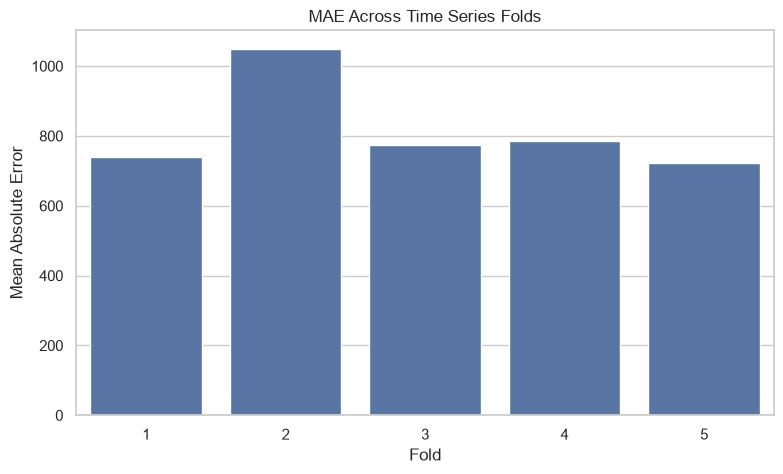

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.barplot(
    data=metrics_df,
    x="Fold",
    y="MAE"
)

plt.title("MAE Across Time Series Folds")
plt.xlabel("Fold")
plt.ylabel("Mean Absolute Error")

plt.show()        



In [ ]:
last_result = fold_results[-1]

y_actual = last_result["y_test"]
y_pred = last_result["y_pred"] 

In [ ]:
comparison = pd.DataFrame({
    "Date": model_df.loc[
        y_actual.index, "Date"
    ].values,
    "Actual": np.asarray(y_actual),
    "Predicted": np.asarray(y_pred)
})

In [67]:
comparison = pd.DataFrame({
    "Date": model_df.loc[
        last_result["X_test"].index, "Date"
    ].values,
    "Actual": np.asarray(last_result["y_test"]),
    "Predicted": np.asarray(last_result["y_pred"])
})

In [68]:
daily_comparison = (
    comparison.groupby("Date")[["Actual", "Predicted"]]
    .sum()
    .reset_index()
)

daily_comparison.head()

,Date,Actual,Predicted
0,2015-03-06,1777211,1767727.000
1,2015-03-07,6565020,6497397.000
2,2015-03-08,201341,211435.875
3,2015-03-09,6765029,6285906.000
4,2015-03-10,6211021,6251482.500


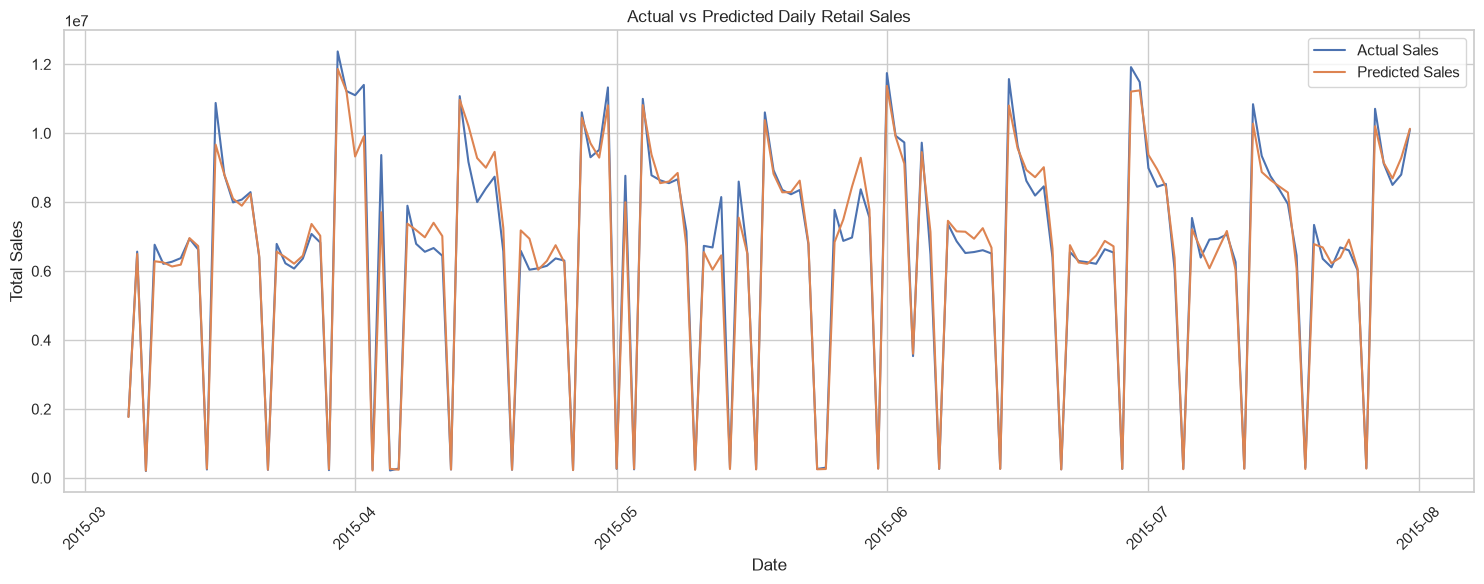

In [69]:
plt.figure(figsize=(15, 6))

plt.plot(
    daily_comparison["Date"],
    daily_comparison["Actual"],
    label="Actual Sales"
)

plt.plot(
    daily_comparison["Date"],
    daily_comparison["Predicted"],
    label="Predicted Sales"
)

plt.title("Actual vs Predicted Daily Retail Sales")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

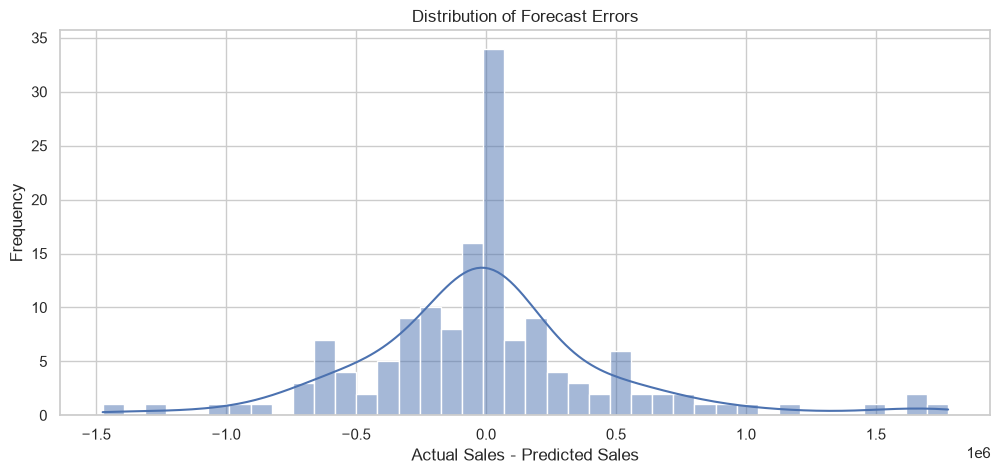

In [70]:
daily_comparison["Error"] = (
    daily_comparison["Actual"]
    - daily_comparison["Predicted"]
)

plt.figure(figsize=(12, 5))

sns.histplot(
    daily_comparison["Error"],
    bins=40,
    kde=True
)

plt.title("Distribution of Forecast Errors")
plt.xlabel("Actual Sales - Predicted Sales")
plt.ylabel("Frequency")

plt.show()

In [71]:
baseline_actual = last_result["y_test"]

baseline_pred = last_result["X_test"]["Lag_7"]

baseline_mae = mean_absolute_error(
    baseline_actual,
    baseline_pred
)

model_mae = mean_absolute_error(
    baseline_actual,
    last_result["y_pred"]
)

print("Baseline MAE:", round(baseline_mae, 2))
print("XGBoost MAE:", round(model_mae, 2))

Baseline MAE: 2375.51
XGBoost MAE: 721.65


In [72]:
final_model = fold_results[-1]["model"]

print("Final model selected successfully!")

Final model selected successfully!


In [73]:
history = model_df.copy()

history["Date"] = pd.to_datetime(history["Date"])

history = history.sort_values(
    ["Store", "Date"]
).reset_index(drop=True)

last_date = history["Date"].max()

print("Last historical date:", last_date)
print("Number of stores:", history["Store"].nunique())

Last historical date: 2015-07-31 00:00:00
Number of stores: 1115


In [74]:
forecast_days = 7

future_dates = pd.date_range(
    start=last_date + pd.Timedelta(days=1),
    periods=forecast_days,
    freq="D"
)

future_dates

DatetimeIndex(['2015-08-01', '2015-08-02', '2015-08-03', '2015-08-04',
               '2015-08-05', '2015-08-06', '2015-08-07'],
              dtype='datetime64[ns]', freq='D')

In [75]:
# Build a history of sales for each store
sales_history = {}

for store_id, group in history.groupby("Store"):
    sales_history[store_id] = list(
        group.sort_values("Date")["Sales"].astype(float)
    )

# Get the latest known calendar values for store-level inputs
store_info = (
    history.sort_values("Date")
    .groupby("Store")
    .tail(1)
    .set_index("Store")
)

forecast_rows = []

for date in future_dates:

    day_predictions = []

    for store_id, sales_values in sales_history.items():

        # Calendar features
        day_of_week = date.dayofweek

        # Lag features use the latest available history
        lag_1 = sales_values[-1]
        lag_7 = sales_values[-7]
        lag_14 = sales_values[-14]
        lag_30 = sales_values[-30]

        rolling_7 = np.mean(sales_values[-7:])
        rolling_30 = np.mean(sales_values[-30:])

        row = {
            "Store": store_id,
            "DayOfWeek": day_of_week,
            "Promo": 0,
            "SchoolHoliday": 0,
            "Year": date.year,
            "Month": date.month,
            "Day": date.day,
            "WeekOfYear": int(date.isocalendar().week),
            "IsWeekend": int(day_of_week >= 5),
            "Lag_1": lag_1,
            "Lag_7": lag_7,
            "Lag_14": lag_14,
            "Lag_30": lag_30,
            "Rolling_7": rolling_7,
            "Rolling_30": rolling_30
        }

        input_df = pd.DataFrame([row])[features]

        prediction = float(final_model.predict(input_df)[0])
        prediction = max(0, prediction)

        day_predictions.append({
            "Date": date,
            "Store": store_id,
            "Predicted_Sales": prediction
        })

    # Add predictions to the store histories after predicting the whole day
    for item in day_predictions:
        sales_history[item["Store"]].append(
            item["Predicted_Sales"]
        )

    forecast_rows.extend(day_predictions)

forecast_df = pd.DataFrame(forecast_rows)

forecast_df.head()

,Date,Store,Predicted_Sales
0,2015-08-01,1,3721.562256
1,2015-08-01,2,2464.547607
2,2015-08-01,3,4917.786133
3,2015-08-01,4,9727.777344
4,2015-08-01,5,2075.155518


In [76]:
daily_forecast = (
    forecast_df.groupby("Date")["Predicted_Sales"]
    .sum()
    .reset_index()
)

daily_forecast

,Date,Predicted_Sales
0,2015-08-01,6.657482e+06
1,2015-08-02,6.918410e+06
2,2015-08-03,7.781291e+06
3,2015-08-04,6.921550e+06
4,2015-08-05,6.873927e+06
5,2015-08-06,6.705718e+06
6,2015-08-07,6.753526e+06


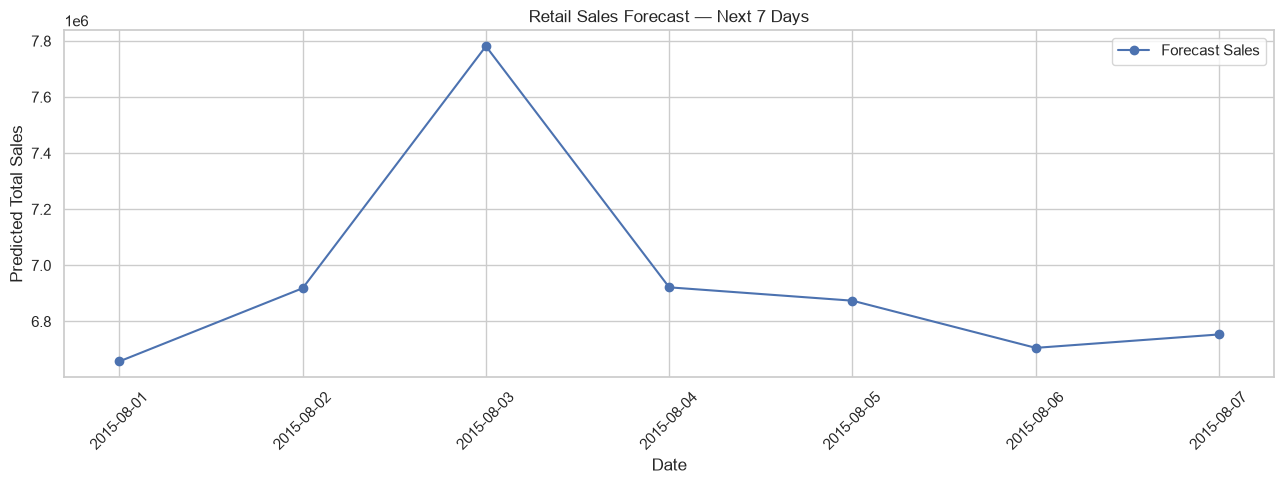

In [77]:
plt.figure(figsize=(13, 5))

plt.plot(
    daily_forecast["Date"],
    daily_forecast["Predicted_Sales"],
    marker="o",
    label="Forecast Sales"
)

plt.title("Retail Sales Forecast — Next 7 Days")
plt.xlabel("Date")
plt.ylabel("Predicted Total Sales")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [78]:
total_forecast = daily_forecast["Predicted_Sales"].sum()
average_forecast = daily_forecast["Predicted_Sales"].mean()

print("Forecast horizon:", forecast_days, "days")
print("Expected total sales:", round(total_forecast, 2))
print("Expected average daily sales:", round(average_forecast, 2))

Forecast horizon: 7 days
Expected total sales: 48611903.82
Expected average daily sales: 6944557.69


In [79]:
store_performance = (
    model_df.groupby("Store")
    .agg(
        Total_Sales=("Sales", "sum"),
        Average_Daily_Sales=("Sales", "mean"),
        Sales_Days=("Sales", "count")
    )
    .reset_index()
)

store_performance = store_performance.sort_values(
    "Total_Sales", ascending=False
)

display(store_performance.head(10))

,Store,Total_Sales,Average_Daily_Sales,Sales_Days
261,262,18969765,20800.180921,912
561,562,16418008,18002.201754,912
816,817,16341174,21672.644562,754
1113,1114,15661876,20771.718833,754
250,251,14340390,19146.048064,749
512,513,13693115,18160.629973,754
732,733,13678952,14998.850877,912
787,788,13562269,17987.094164,754
382,383,12992061,17322.748000,750
755,756,12467769,16645.886515,749


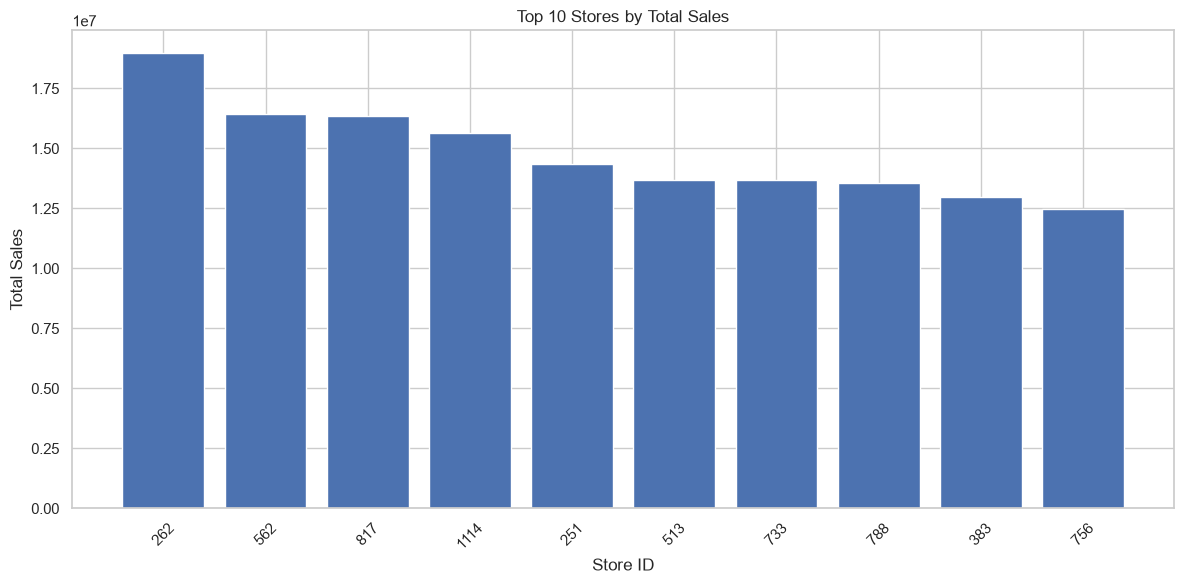

In [80]:
import matplotlib.pyplot as plt

top_stores = store_performance.head(10)

plt.figure(figsize=(12, 6))
plt.bar(
    top_stores["Store"].astype(str),
    top_stores["Total_Sales"]
)
plt.title("Top 10 Stores by Total Sales")
plt.xlabel("Store ID")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [81]:
promo_analysis = (
    model_df.groupby("Promo")["Sales"]
    .agg(["mean", "median", "count"])
    .reset_index()
)

promo_analysis.columns = [
    "Promo", "Average_Sales", "Median_Sales", "Number_of_Records"
]

display(promo_analysis)

,Promo,Average_Sales,Median_Sales,Number_of_Records
0,0,5947.060699,5475.0,447386
1,1,8247.755922,7666.0,363556


In [82]:
store_forecast = (
    forecast_df.groupby("Store")["Predicted_Sales"]
    .agg(["sum", "mean"])
    .reset_index()
)

store_forecast.columns = [
    "Store", "Forecast_7_Day_Total", "Average_Daily_Forecast"
]

store_forecast = store_forecast.sort_values(
    "Forecast_7_Day_Total", ascending=False
)

display(store_forecast.head(10))

,Store,Forecast_7_Day_Total,Average_Daily_Forecast
1113,1114,142314.582031,20330.654576
841,842,138548.828125,19792.689732
261,262,137675.992188,19667.998884
816,817,131501.790039,18785.970006
250,251,129212.880859,18458.982980
382,383,118257.845703,16893.977958
512,513,117954.198242,16850.599749
561,562,117073.853516,16724.836217
826,827,116424.263672,16632.037667
787,788,113522.924805,16217.560686


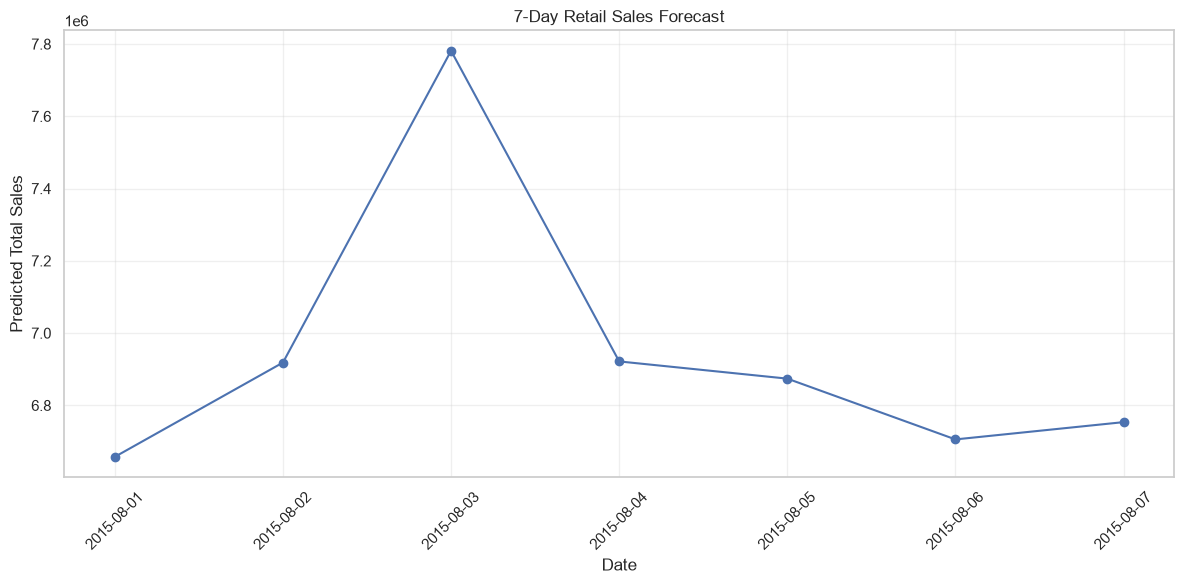

In [83]:
plt.figure(figsize=(12, 6))

plt.plot(
    daily_forecast["Date"],
    daily_forecast["Predicted_Sales"],
    marker="o"
)

plt.title("7-Day Retail Sales Forecast")
plt.xlabel("Date")
plt.ylabel("Predicted Total Sales")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [84]:
top_store = store_performance.iloc[0]
best_forecast_store = store_forecast.iloc[0]

promo_0 = promo_analysis.loc[
    promo_analysis["Promo"] == 0, "Average_Sales"
].mean()

promo_1 = promo_analysis.loc[
    promo_analysis["Promo"] == 1, "Average_Sales"
].mean()

print("BUSINESS INSIGHTS AND RECOMMENDATIONS")
print("=" * 45)

print(
    f"1. Top historical store: Store {int(top_store['Store'])}"
)
print(
    f"   Average daily sales: {top_store['Average_Daily_Sales']:.2f}"
)

print(
    f"\n2. Highest forecasted store: "
    f"Store {int(best_forecast_store['Store'])}"
)
print(
    f"   Predicted 7-day sales: "
    f"{best_forecast_store['Forecast_7_Day_Total']:.2f}"
)

if pd.notna(promo_0) and pd.notna(promo_1):
    difference = promo_1 - promo_0
    percentage = difference / promo_0 * 100 if promo_0 != 0 else float("nan")

    print("\n3. Promotion analysis")
    print(f"   Average sales without promotion: {promo_0:.2f}")
    print(f"   Average sales with promotion: {promo_1:.2f}")
    print(f"   Difference: {difference:.2f}")
    print(f"   Percentage difference: {percentage:.2f}%")

print("\n4. Recommended business actions")
print("   - Prioritize inventory planning using store-level forecasts.")
print("   - Investigate why top-performing stores achieve higher sales.")
print("   - Evaluate promotions using sales uplift and campaign costs.")
print("   - Review forecast errors before making inventory decisions.")

BUSINESS INSIGHTS AND RECOMMENDATIONS
1. Top historical store: Store 262
   Average daily sales: 20800.18

2. Highest forecasted store: Store 1114
   Predicted 7-day sales: 142314.58

3. Promotion analysis
   Average sales without promotion: 5947.06
   Average sales with promotion: 8247.76
   Difference: 2300.70
   Percentage difference: 38.69%

4. Recommended business actions
   - Prioritize inventory planning using store-level forecasts.
   - Investigate why top-performing stores achieve higher sales.
   - Evaluate promotions using sales uplift and campaign costs.
   - Review forecast errors before making inventory decisions.
